In [4]:
import numpy as np
import pandas as pd
import xarray as xr
import glob, json
import matplotlib
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point

import warnings
warnings.filterwarnings('ignore')

from utils.pyfunctions import *

### Spin up stability evaluation

In [5]:
utils_path = '../utils/'
la=xr.open_dataset(os.path.join(utils_path, "sparsegrid_landarea.nc")).landarea

def calc_drift(ds,var,la):
    # only use for carbon pool variables (TOTECOSYSC, TOTVEGC, TOTSOMC)
    # unit conversion: gC/m2 -> PgC/yr
    dx=(ds[var]-ds[var].shift(year=20))
    drift=1e-9*(la*dx.isel(year=range(20,40)).mean(dim='year')).sum(dim='gridcell')/20
    return drift

def calc_diseq(ds,grams):
    dx=(ds-ds.shift(year=20))
    diseq=100*(la*(abs(dx.isel(year=slice(-20, None)).mean(dim='year'))>20*grams)).sum(dim='gridcell')/la.sum()
    return diseq.values

In [6]:
ds_psasu = xr.open_dataset('/glade/work/linnia/CLM6-PPE/ctsm53065_lhc/postp/ctsm53065_lhc_grid_postSASU.nc')

da = ds_psasu.TOTECOSYSC_amean.isel(year=slice(80,120))
diseq = calc_diseq(da,1)
drift = calc_drift(ds_psasu,'TOTECOSYSC_amean',la)

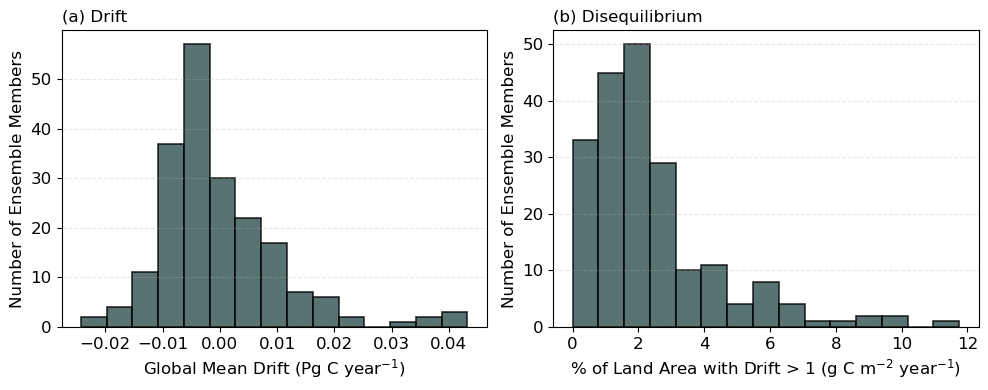

In [7]:
cf = la.sum()*1E-9

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Drift histogram
axes[0].hist(drift, color='darkslategrey', edgecolor='black', linewidth=1.2, bins=15, alpha=0.8)
axes[0].set_xlabel('Global Mean Drift (Pg C year$^{-1}$)', fontsize=12)
axes[0].set_ylabel('Number of Ensemble Members', fontsize=12)
axes[0].set_title('(a) Drift', fontsize=12, loc='left')
axes[0].grid(axis='y', alpha=0.3, linestyle='--')
axes[0].tick_params(labelsize=12)

# Disequilibrium histogram
axes[1].hist(diseq, color='darkslategrey', edgecolor='black', linewidth=1.2, bins=15, alpha=0.8)
axes[1].set_xlabel('% of Land Area with Drift > 1 (g C m$^{-2}$ year$^{-1}$)', fontsize=12)
axes[1].set_ylabel('Number of Ensemble Members', fontsize=12)
axes[1].set_title('(b) Disequilibrium', fontsize=12, loc='left')
axes[1].grid(axis='y', alpha=0.3, linestyle='--')
axes[1].tick_params(labelsize=12)

plt.tight_layout()
plt.savefig('../figs/SI_spinup_eval.png', dpi=300, bbox_inches='tight')

### Fig1 N params

In [8]:
label = ['Plant Hydraulics','Stomatal Conductance','Photosynthetic Capacity and Acclimation','Plant Respiration',
         'Carbon & Nitrogen Allocation','Fixation & Uptake of Nitrogen','Vegetation Phenology',
         'Mortality','Decomposition','Latent, Sensible & Momentum Fluxes','Radiation',
         'Hydrology','Snow Processes','Fire']
nparams = [2,2,12,2,2,2,3,1,8,4,1,10,5,2]

In [9]:
n_pft_params = [2,2,2,1,2,1,1,1,0,1,1,0,0,1]
n_u_params = np.array(nparams)-np.array(n_pft_params)

In [10]:
factorial_paramcount = np.array(n_u_params)+13*np.array(n_pft_params)

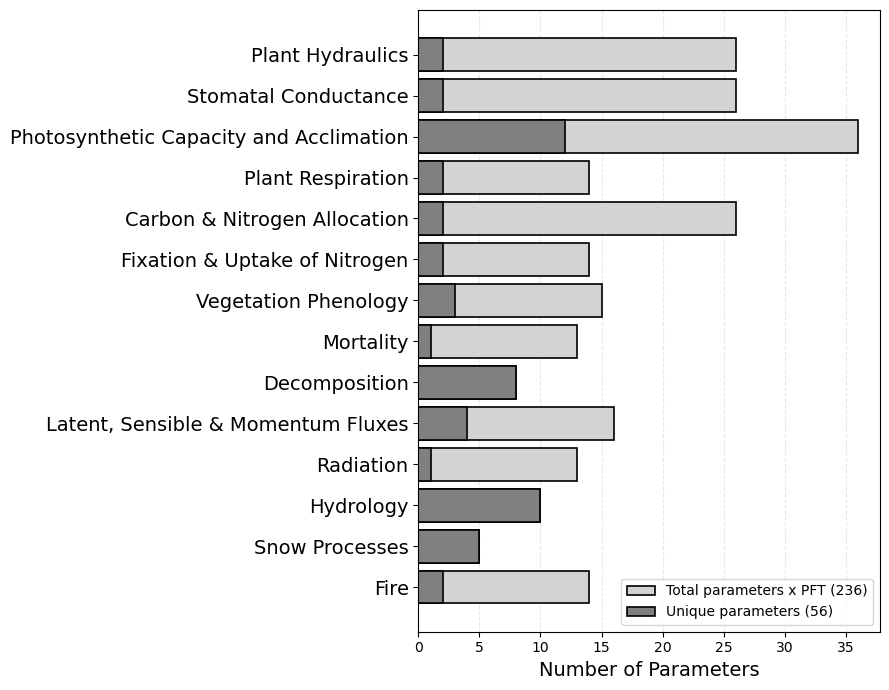

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
#colors = plt.cm.tab20(np.linspace(0, 1, len(nparams)))
bars = ax.barh(range(len(nparams)), factorial_paramcount, color='lightgrey', edgecolor='black', linewidth=1.2,label='Total parameters x PFT (236)')
bars = ax.barh(range(len(nparams)), nparams, color='grey', edgecolor='black', linewidth=1.2,label='Unique parameters (56)')
ax.invert_yaxis()
ax.set_yticks(range(len(nparams)))
#ax.set_xticklabels(np.arange(0,15,2),fontsize=12)
ax.set_yticklabels(label, fontsize=14)
ax.set_xlabel('Number of Parameters', fontsize=14)
ax.grid(axis='x', alpha=0.3, linestyle='--', linewidth=0.8)
ax.set_axisbelow(True)

plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../figs/figure1_parameters.png', dpi=300, bbox_inches='tight')

### Biomes Map

In [13]:
ds_biome_maps = xr.open_dataset('../biomes/biome_masks.nc')

In [14]:
biome_names = ['Tropical rainforest','Tropical savanna','Subtropical savanna','Grasslands','Shrublands','Temperate woodland','Temperate mixed forest',
               'Evergreen forest','Boreal forest','Cold deciduous forest','Boreal mixed forest','Boreal shrubland','Tundra','Other']


In [15]:
from matplotlib.colors import ListedColormap, BoundaryNorm

N = len(biome_names)
bounds = np.arange(N+1)
norm = BoundaryNorm(bounds, N)

colors = [
    "#004D19","#5D9945","darkseagreen",  # (tropic, tropic, savanna,)
    "#DECAA7", "#D2B48C", # (grasslands, shrublands)
    "#859457","#A1AF78","lightblue","cadetblue","teal",# (mixed decid, conifer, larch)
    "thistle","lavenderblush","lavender", # (boreal forest, aspen, boreal shrub, tundra)
    "grey",
]

cmap = ListedColormap(colors, name="earth_biomes_19")

In [16]:
#dat=xr.open_dataset('/glade/campaign/cgd/tss/projects/PPE/ctsm53065_lhc/hist/ctsm5.3.065_transient_lhc0066.clm2.h0a.2020-02-01-00000.nc')

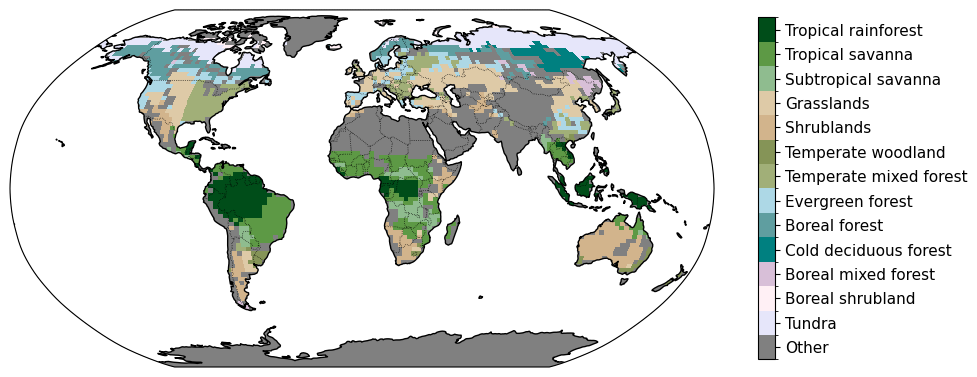

In [18]:
lat_values = ds_biome_maps.lat.values
lon_values = ds_biome_maps.lon.values

biomes = ds_biome_maps.biomes.where(ds_biome_maps.biomes != 0, 14)

fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.Robinson()})
ocean = ax.add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '110m',facecolor='white'))
mesh = ax.pcolormesh(lon_values, lat_values, biomes-1, transform=ccrs.PlateCarree(), cmap=cmap, norm=norm, shading='auto')
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5)
#ax.scatter(dat.grid1d_lon, dat.grid1d_lat, transform=ccrs.PlateCarree(),
#            marker='+', s=15, c='k', linewidths=0.6)

cbar = plt.colorbar(mesh, ticks=np.arange(N) + 0.5, shrink=0.6)
cbar.set_ticklabels(np.array(biome_names), fontsize=11)
cbar.ax.invert_yaxis()

plt.tight_layout()
plt.savefig('../figs/figure2_biomes.png',dpi = 300)

### PFT parameter ranges

In [19]:
#get the pft names
pfts=xr.open_dataset('/glade/campaign/asp/djk2120/PPEn11/paramfiles/OAAT0000.nc').pftname
pfts=[str(p)[2:-1].strip() for p in pfts.values][0:17]

# get the param names
utils_dir = '/glade/u/home/linnia/CLM6-PPE/utils/'
with open(os.path.join(utils_dir, "param_info.json"), "r") as f:
    param_info = json.load(f)
universal_param_names = param_info['u_params']
pft_param_names = param_info['pft_params']


In [20]:
df = pd.read_csv('clm6ppe_paramranges_12112025.csv')

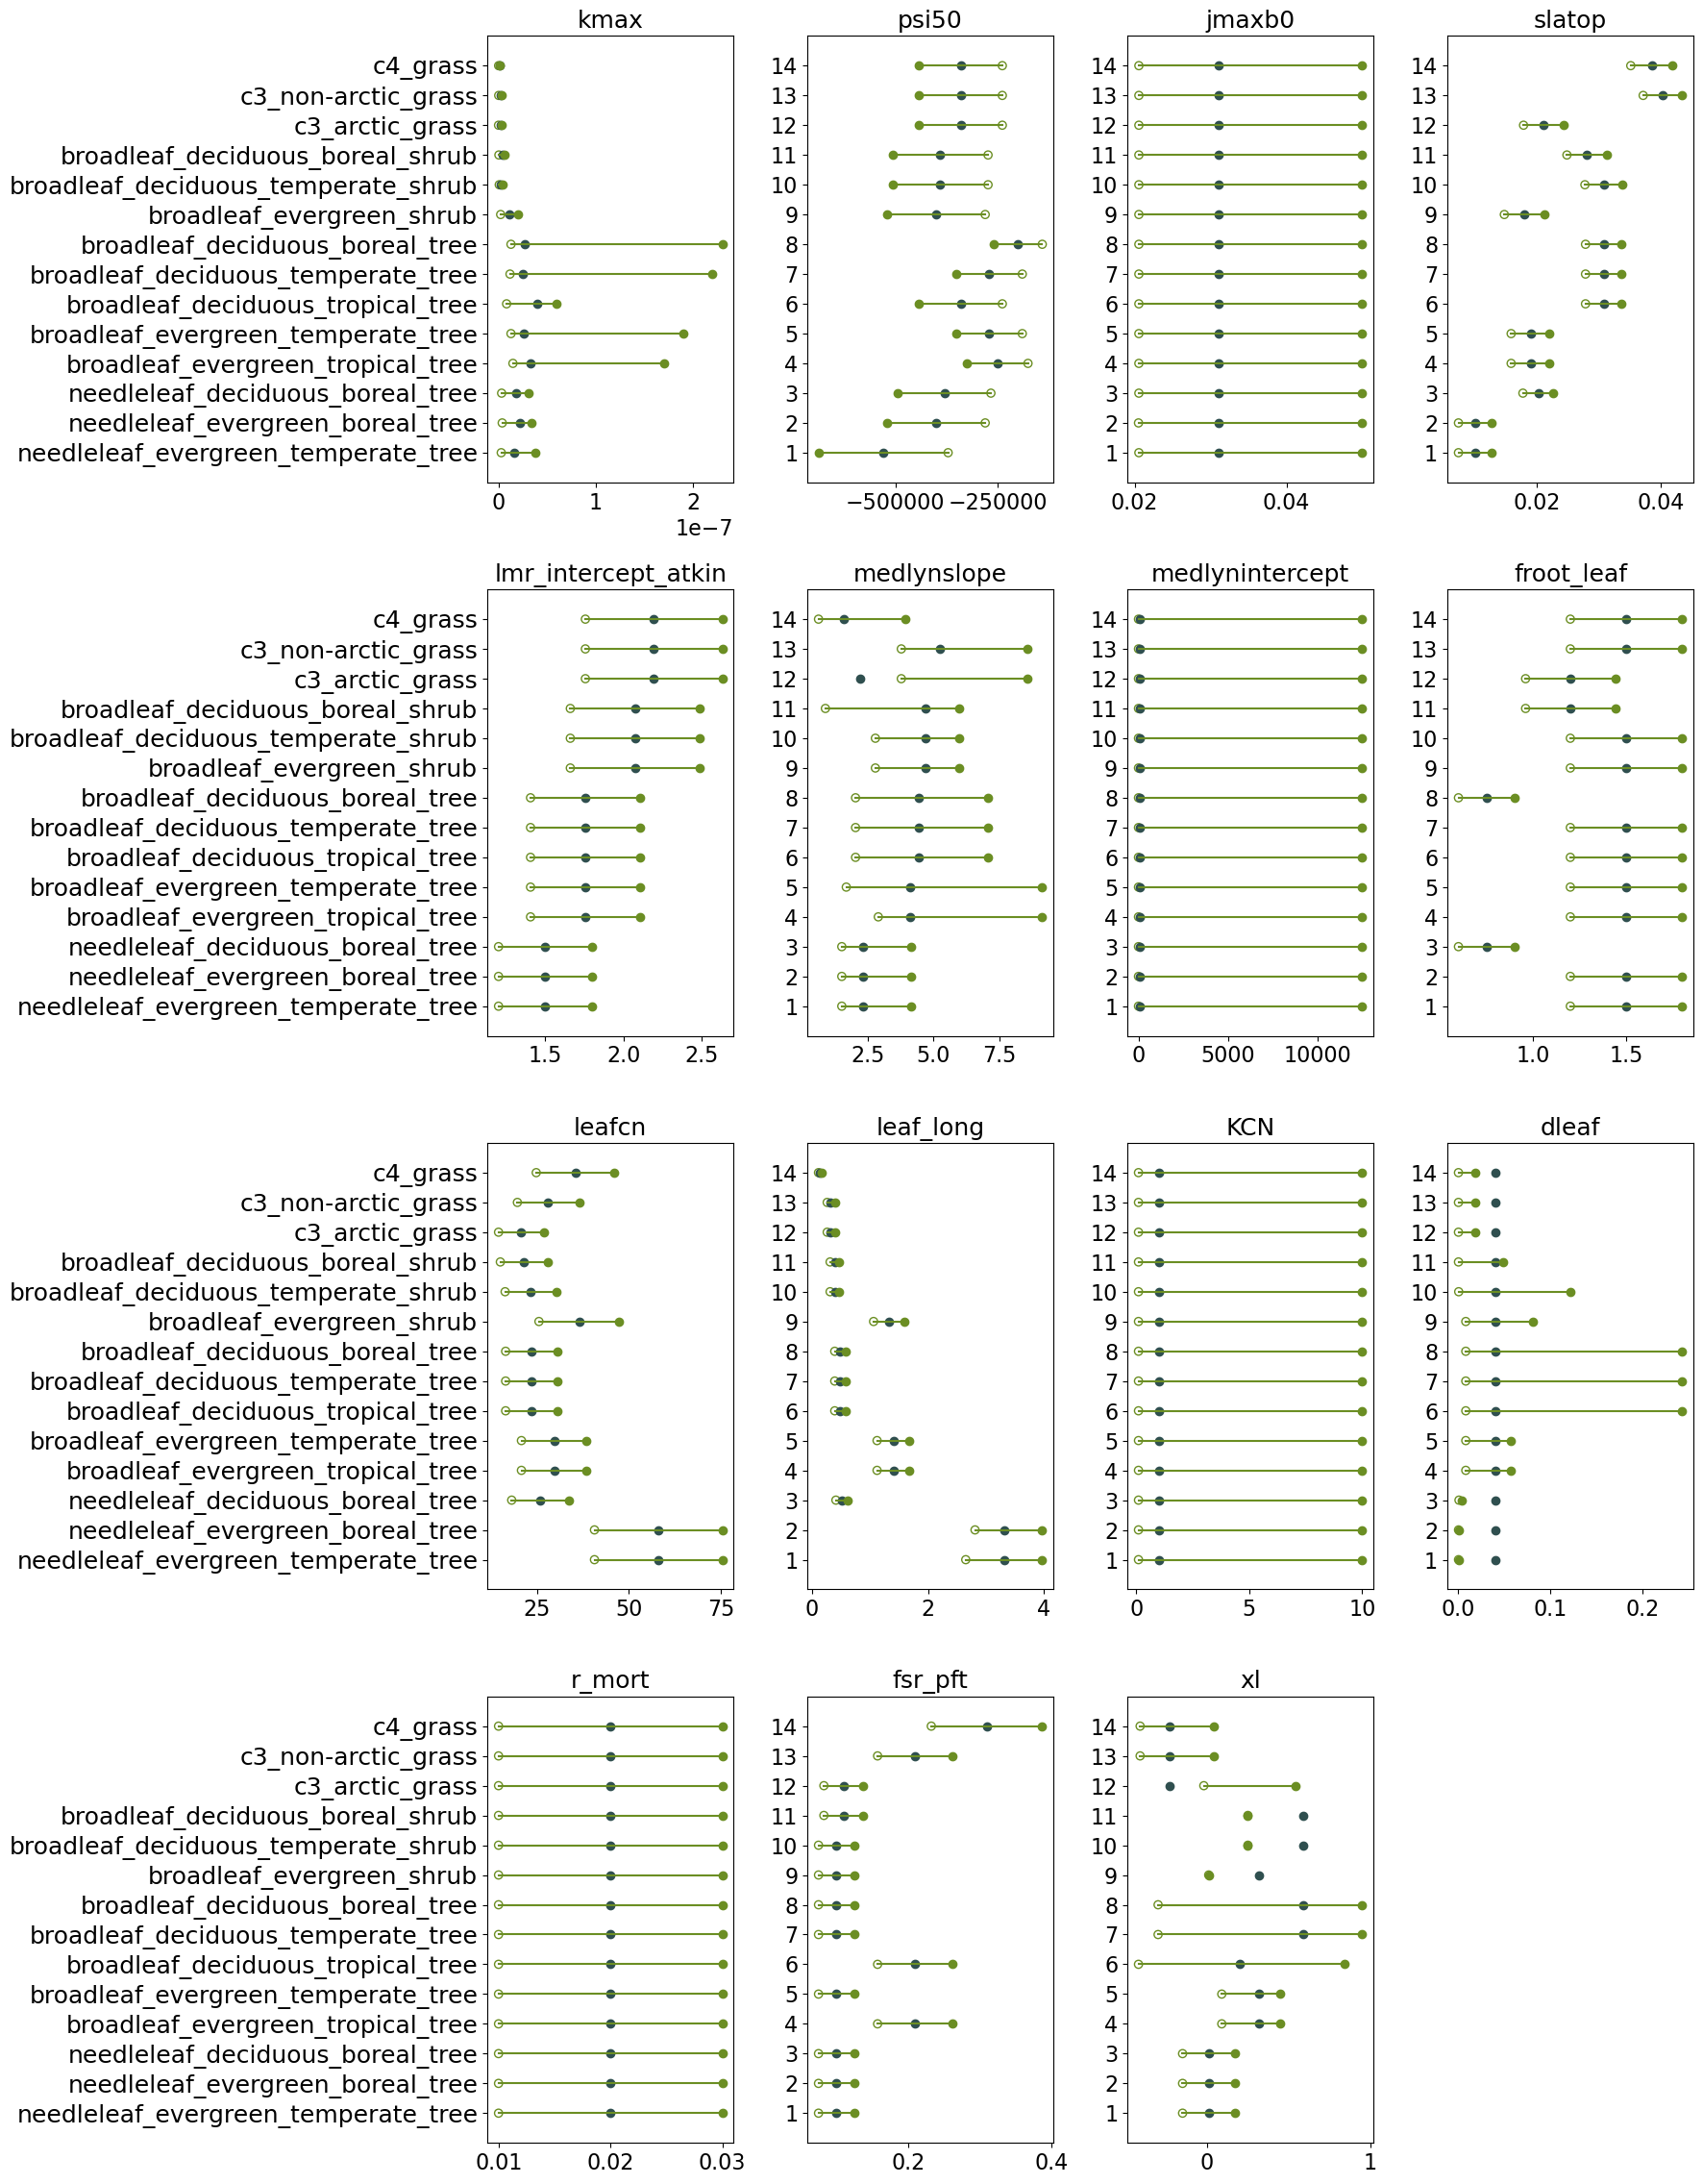

In [21]:
plt.figure(figsize=[18,23])
plt.rcParams.update({'font.size': 16})
for i,param in enumerate(pft_param_names):
    ax = plt.subplot(4,4,i+1)
    pft_mins_str = df[df['param'] == param]['pft_mins'].values[0]
    pft_mins = np.array([float(x) for x in pft_mins_str.split(',')])
    pft_maxs_str = df[df['param'] == param]['pft_maxs'].values[0]
    pft_maxs = np.array([float(x) for x in pft_maxs_str.split(',')])
    pft_defs_str = df[df['param'] == param]['pft_defaults'].values[0]
    pft_defs = np.array([float(x) for x in pft_defs_str.split(',')])
    
    for p in range(1,15):
        d = pft_defs[p]
        mn = pft_mins[p]
        mx = pft_maxs[p]
        ax.plot([mn,mx],[p,p],color='olivedrab')
        ax.scatter(mn,p,color='olivedrab',marker='o',facecolors='none',label='minimum')
        ax.scatter(d,p,color='darkslategrey',label='default')
        ax.scatter(mx,p,color='olivedrab',marker='o',label='maximum')
        ax.set_yticks(range(1,15))
        ax.set_ylim([0,15])
    plt.title(param,fontsize=18)
    if (i%4 == 0):
        ax.set_yticks(range(1,15))
        ax.set_yticklabels(pfts[1:15],fontsize=18)
    
plt.tight_layout()
plt.savefig('../figs/SI_PFT_parameter_ranges.png',dpi=300)